**Phase 3a - Concentration evaluation**

Estimate CO, NOx, and NO2 concentrations from hour, weather and the four selected low-cost sensors only:
$$\hat{c}_g = \sum_{j} P(B_g = j \mid \text{hour, T, RH, S1, S3, S4, S5}) \cdot \bar{c}_{g,j}$$

where each bin average $\bar{c}_{g,j}$ is calculated from the training split only.

The primary output is the vector of estimated gas concentrations.

**Evaluation principles**
* **Gases**: CO, NOx, NO2. C6H6 is excluded because it behaves almost like a transform of S2; NMHC is excluded because it is too sparse.
* **Sensors:** S1, S3, S4, S5. S2 is excluded.
* **Weather evidence:** temperature (T) and relative humidity (RH); AH is not used.
* **Network:** each gas has hour as its parent. Sensor parents are specified below, with T and RH included for each sensor.
* **Splits:** blocked train/validation/test splits. Discretizer edges and gas-bin means are learned from training data only.
* **Concentration scoring:** MAE and RMSE against observed raw gas concentrations, with a perfect-bin resolution floor for context. The bin count is selected on validation MAE only.

In [ ]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cse250a.modules.config import config
from cse250a.modules.core import TIME_CARDS, Gas, Network, Sensor, Time, Weather
from cse250a.modules.data import Discretizer, blocked_split, load_air_quality
from cse250a.modules.eval.concentration import (
    bin_means,
    concentration_error,
    expected_concentration,
    resolution_floor,
)
from cse250a.modules.eval.skill import skill_vs_baseline
from cse250a.modules.models import HourOnlyBaseline, LayeredBN

SEEDS = (0, 1, 2)
BIN_COUNTS = (3, 5)
ALPHA = config.bins.alpha

GASES = (Gas.CO, Gas.NOX, Gas.NO2)
SENSORS = (Sensor.S1, Sensor.S3, Sensor.S4, Sensor.S5)
WEATHER = (Weather.T, Weather.RH)
EVIDENCE = (Time.HOUR, *WEATHER, *SENSORS)

PHASE = "phase3a"


plt.rcParams.update(
    {"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False}
)

print("Gases", GASES)
print("Sensors", SENSORS)
print("Weather", WEATHER)

Gases (<Gas.CO: 'CO(GT)'>, <Gas.NOX: 'NOx(GT)'>, <Gas.NO2: 'NO2(GT)'>)
Sensors (<Sensor.S1: 'PT08.S1(CO)'>, <Sensor.S3: 'PT08.S3(NOx)'>, <Sensor.S4: 'PT08.S4(NO2)'>, <Sensor.S5: 'PT08.S5(O3)'>)
Weather (<Weather.T: 'T'>, <Weather.RH: 'RH'>)


**1. Load the data and define the Phase 2 network**
The Phase 2 edges are:
* S1 $\leftarrow$ CO
* S3 $\leftarrow$ NOx
* S4 $\leftarrow$ NO2, CO, NOx
* S5 $\leftarrow$ CO, NOx

Every sensor also has T and RH as parents. The gas nodes each have hour as their parent. Gas references are prediction targets, never evidence.

In [ ]:
raw = load_air_quality(config.paths.air_quality_csv)

# Phase 2 requires observed input variables. Do not drop rows just because a
# reference gas or a sensor is missing: the BN can handle missing observations.
before = len(raw)
raw = raw.dropna(subset=[Time.HOUR, *WEATHER]).copy()
print(f"Rows: {len(raw):,} (removed {before - len(raw):,} with missing hour/weather)")
print("Date range:", raw.index.min(), "to", raw.index.max())

GAS_PARENTS = {
    Sensor.S1: (Gas.CO,),
    Sensor.S3: (Gas.NOX,),
    Sensor.S4: (Gas.NO2, Gas.CO, Gas.NOX),
    Sensor.S5: (Gas.CO, Gas.NOX),
}


def make_network(cards):
    structure = {g: (Time.HOUR,) for g in GASES}
    structure.update({sensor: (*GAS_PARENTS[sensor], *WEATHER) for sensor in SENSORS})
    return Network(structure=structure, cards=cards).validate()


# Quick data-availability check for the three reference gases.
availability = pd.DataFrame(
    {
        "observed": raw[list(GASES)].notna().sum(),
        "missing": raw[list(GASES)].isna().sum(),
        "missing_pct": 100 * raw[list(GASES)].isna().mean(),
    }
)
display(availability)

preview_train, _, _ = blocked_split(raw, seed=SEEDS[0])
preview_disc = Discretizer(n_bins=BIN_COUNTS[0]).fit(
    preview_train, [*GASES, *SENSORS, *WEATHER]
)
preview_cards = {**preview_disc.cards, **TIME_CARDS}
network_preview = make_network(preview_cards)
print(network_preview)

Rows: 8,991 (removed 366 with missing hour/weather)
Date range: 2004-03-10 18:00:00 to 2005-04-04 14:00:00


,observed,missing,missing_pct
CO(GT),7344,1647,18.318318
NOx(GT),7396,1595,17.739962
NO2(GT),7393,1598,17.773329


Network(7 nodes, inputs: hour, T, RH)
          CO(GT) | hour                          CPT shape (24, 3)
         NOx(GT) | hour                          CPT shape (24, 3)
         NO2(GT) | hour                          CPT shape (24, 3)
     PT08.S1(CO) | CO(GT), T, RH                 CPT shape (3, 3, 3, 3)
    PT08.S3(NOx) | NOx(GT), T, RH                CPT shape (3, 3, 3, 3)
    PT08.S4(NO2) | NO2(GT), CO(GT), NOx(GT), T, RH  CPT shape (3, 3, 3, 3, 3, 3)
     PT08.S5(O3) | CO(GT), NOx(GT), T, RH        CPT shape (3, 3, 3, 3, 3)


**2. Helper functions**

The concentration estimator and concentration error functions are imported from the project's shared evaluation helpers. The two helpers below only wire a model to them.

In [ ]:
def make_bin_means(train_raw, train_binned):
    """Training-only representative raw concentration for each gas bin."""
    return {gas: bin_means(train_raw[gas], train_binned[gas]) for gas in GASES}


def estimate_all(model, binned, bin_means_by_gas):
    """Return the concentration vector and per-gas posterior bin probabilities."""
    estimates = {}
    probabilities = {}
    for gas in GASES:
        proba = model.predict_proba(binned, gas, EVIDENCE)
        probabilities[gas] = proba
        estimates[gas] = expected_concentration(proba, bin_means_by_gas[gas])
    return pd.DataFrame(estimates, index=binned.index), probabilities

**3. Run the validation grid**
For each bin count and split seed:
1. Make a blocked train/validation/test split
2. Fit the discretizer on **train only** using the three gases, four sensors, and T/RH.
3. Fit the specified Bayesian network and the hour-only baseline.
4. Estimate each gas concentration as posterior bin probabilities multiplied by training bin means.
5. Score concentration MAE/RMSE and the perfect-bin resolution floor.

In [ ]:
concentration_rows = []
validation_cache = {}
model_cache = {}

for n_bins in BIN_COUNTS:
    for seed in SEEDS:
        train_raw, val_raw, test_raw = blocked_split(raw, seed=seed)

        discretizer = Discretizer(n_bins=n_bins).fit(
            train_raw, [*GASES, *SENSORS, *WEATHER]
        )
        train = discretizer.transform(train_raw)
        val = discretizer.transform(val_raw)
        test = discretizer.transform(test_raw)
        cards = {**discretizer.cards, **TIME_CARDS}

        network = make_network(cards)
        bn = LayeredBN(network, alpha=ALPHA, seed=seed).fit(train)
        hour = HourOnlyBaseline(cards=cards, alpha=ALPHA).fit(train)

        c_bar = make_bin_means(train_raw, train)

        bn_est, bn_proba = estimate_all(bn, val, c_bar)
        hour_est, hour_proba = estimate_all(hour, val, c_bar)

        validation_cache[(n_bins, seed)] = {
            "train_raw": train_raw,
            "val_raw": val_raw,
            "test_raw": test_raw,
            "train": train,
            "val": val,
            "test": test,
            "discretizer": discretizer,
            "cards": cards,
            "c_bar": c_bar,
            "bn_est": bn_est,
            "hour_est": hour_est,
            "bn_proba": bn_proba,
            "hour_proba": hour_proba,
        }
        model_cache[(n_bins, seed)] = {"bn": bn, "hour": hour}

        bn_est.to_csv(
            config.paths.result(PHASE, f"estimates_bn_bins{n_bins}_seed{seed}_val.csv"),
            index_label="datetime",
        )
        hour_est.to_csv(
            config.paths.result(
                PHASE, f"estimates_hour_bins{n_bins}_seed{seed}_val.csv"
            ),
            index_label="datetime",
        )

        for gas in GASES:
            for model_name, estimates in (
                ("BN", bn_est),
                ("HourOnlyBaseline", hour_est),
            ):
                concentration_rows.append(
                    {
                        "bins": n_bins,
                        "seed": seed,
                        "gas": str(gas),
                        "model": model_name,
                        **concentration_error(estimates[gas], val_raw[gas]),
                    }
                )
            concentration_rows.append(
                {
                    "bins": n_bins,
                    "seed": seed,
                    "gas": str(gas),
                    "model": "resolution_floor",
                    **resolution_floor(val_raw[gas], val[gas], c_bar[gas]),
                }
            )

        n_iter = bn.result.n_iter if bn.result is not None else "n/a"
        print(f"Finished bins={n_bins}, seed={seed}; BN EM iterations={n_iter}")

concentration_grid = pd.DataFrame(concentration_rows)
concentration_grid.to_csv(
    config.paths.result(PHASE, "concentration_grid.csv"), index=False
)
print("Saved validation concentration table.")

Finished bins=3, seed=0; BN EM iterations=5


Finished bins=3, seed=1; BN EM iterations=4


Finished bins=3, seed=2; BN EM iterations=4


Finished bins=5, seed=0; BN EM iterations=6


Finished bins=5, seed=1; BN EM iterations=5


Finished bins=5, seed=2; BN EM iterations=5
Saved validation concentration table.


**4. Per-gas concentration results**

Report the mean and standard deviation across the three blocked-split seeds. Every model is scored on observed validation reference readings. Compare the BN with the hour-only baseline and the resolution floor for each gas.

In [ ]:
concentration_summary = (
    concentration_grid.groupby(["bins", "gas", "model"])
    .agg(
        n_mean=("n", "mean"),
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", "std"),
    )
    .reset_index()
)
display(concentration_summary.round(4))

concentration_report = concentration_summary.copy()
concentration_report["MAE (mean ± std)"] = concentration_report.apply(
    lambda row: f"{row['MAE_mean']:.3f} ± {row['MAE_std']:.3f}", axis=1
)
concentration_report["RMSE (mean ± std)"] = concentration_report.apply(
    lambda row: f"{row['RMSE_mean']:.3f} ± {row['RMSE_std']:.3f}", axis=1
)
display(
    concentration_report[
        ["bins", "gas", "model", "n_mean", "MAE (mean ± std)", "RMSE (mean ± std)"]
    ]
)

,bins,gas,model,n_mean,MAE_mean,MAE_std,RMSE_mean,RMSE_std
0,3,CO(GT),BN,1853.0000,0.5437,0.0448,0.8047,0.0679
1,3,CO(GT),HourOnlyBaseline,1853.0000,0.8570,0.0391,1.1511,0.0356
2,3,CO(GT),resolution_floor,1853.0000,0.4608,0.0579,0.7058,0.0937
3,3,NO2(GT),BN,1854.6667,31.0796,2.4407,40.5628,3.5565
4,3,NO2(GT),HourOnlyBaseline,1854.6667,31.9767,2.8023,41.4433,3.9894
5,3,NO2(GT),resolution_floor,1854.6667,16.9806,1.7566,23.1349,3.5182
6,3,NOx(GT),BN,1855.0000,91.7509,0.0736,134.1168,11.7085
7,3,NOx(GT),HourOnlyBaseline,1855.0000,136.4695,5.5857,186.4560,19.5856
8,3,NOx(GT),resolution_floor,1855.0000,74.1312,18.1980,116.9653,26.7962
9,5,CO(GT),BN,1853.0000,0.4875,0.0444,0.7168,0.0634


,bins,gas,model,n_mean,MAE (mean ± std),RMSE (mean ± std)
0,3,CO(GT),BN,1853.000000,0.544 ± 0.045,0.805 ± 0.068
1,3,CO(GT),HourOnlyBaseline,1853.000000,0.857 ± 0.039,1.151 ± 0.036
2,3,CO(GT),resolution_floor,1853.000000,0.461 ± 0.058,0.706 ± 0.094
3,3,NO2(GT),BN,1854.666667,31.080 ± 2.441,40.563 ± 3.556
4,3,NO2(GT),HourOnlyBaseline,1854.666667,31.977 ± 2.802,41.443 ± 3.989
5,3,NO2(GT),resolution_floor,1854.666667,16.981 ± 1.757,23.135 ± 3.518
6,3,NOx(GT),BN,1855.000000,91.751 ± 0.074,134.117 ± 11.709
7,3,NOx(GT),HourOnlyBaseline,1855.000000,136.469 ± 5.586,186.456 ± 19.586
8,3,NOx(GT),resolution_floor,1855.000000,74.131 ± 18.198,116.965 ± 26.796
9,5,CO(GT),BN,1853.000000,0.488 ± 0.044,0.717 ± 0.063


**5. Select the configuration using validation concentration error only**

The bin count is chosen on concentration error. For each (bins, seed) the score is the BN's MAE divided by the hour-only baseline's MAE, averaged over the three gases, so no gas dominates because of its units. Lower is better. The representative seed is the seed whose score is closest to the mean for the chosen bin count.

In [ ]:
mae = concentration_grid.pivot_table(
    index=["bins", "seed", "gas"], columns="model", values="MAE"
)
mae["relative_MAE"] = mae["BN"] / mae["HourOnlyBaseline"]
per_run = mae["relative_MAE"].groupby(["bins", "seed"]).mean().rename("relative_MAE")

selection = per_run.groupby("bins").agg(["mean", "std"])
display(selection.round(4))

CHOSEN_BINS = int(selection["mean"].idxmin())
seed_scores = per_run.loc[CHOSEN_BINS]
CHOSEN_SEED = int((seed_scores - seed_scores.mean()).abs().idxmin())

chosen = validation_cache[(CHOSEN_BINS, CHOSEN_SEED)]

print(
    {
        "selection_criterion": "mean over gases of BN MAE / baseline MAE (validation)",
        "bins": CHOSEN_BINS,
        "representative_seed": CHOSEN_SEED,
    }
)

,mean,std
bins,,
3,0.7603,0.0258
5,0.6933,0.0149


{'selection_criterion': 'mean over gases of BN MAE / baseline MAE (validation)', 'bins': 5, 'representative_seed': 1}


**6. Figures**

The figure below is generated from validation results and saved to figures/phase3a/.

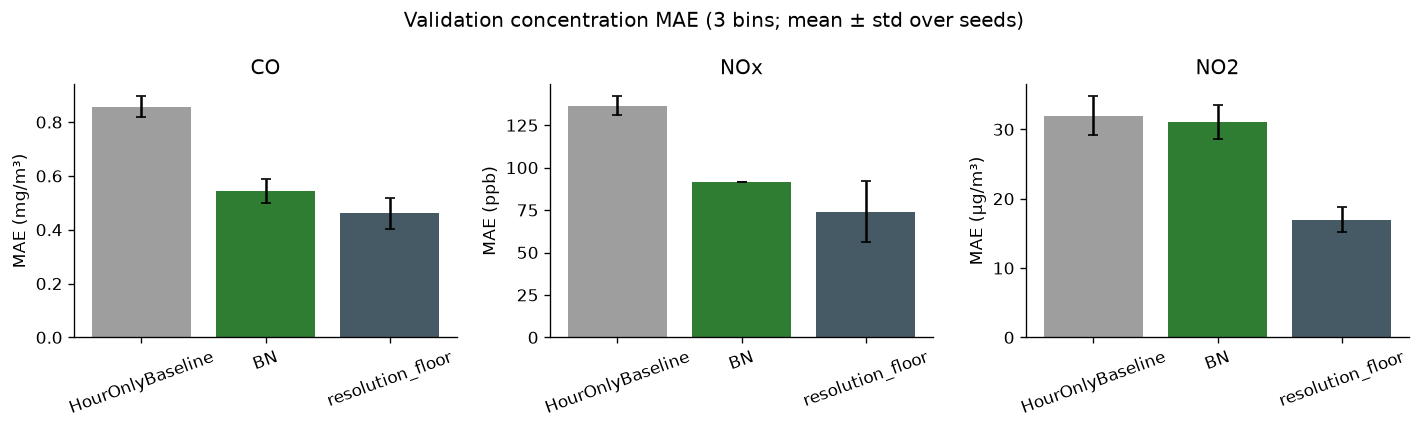

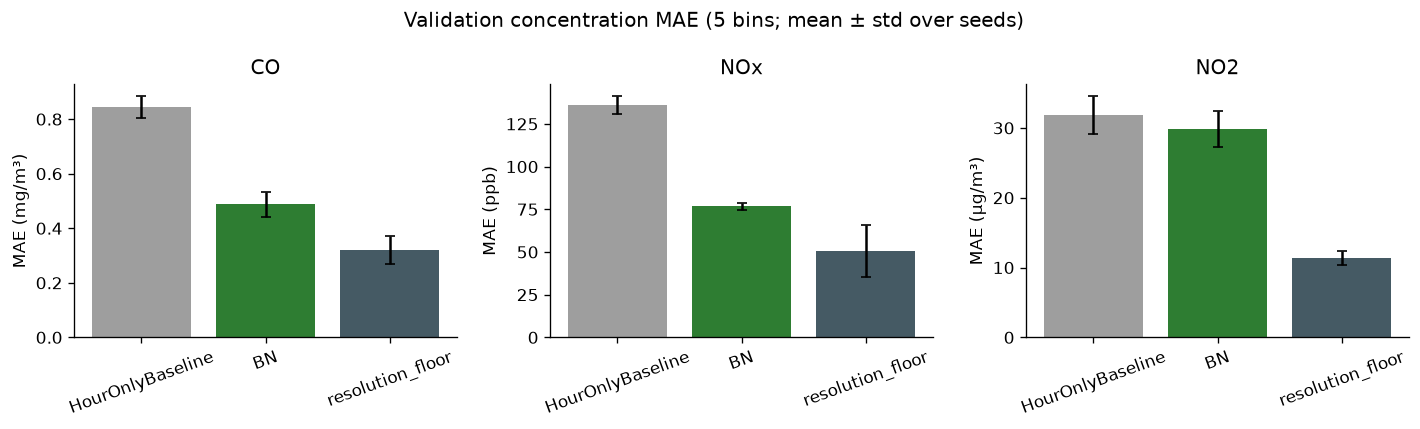

In [ ]:
# Figure 1: concentration MAE by gas and model, one row per bin count, one panel per gas.
UNITS = {"CO": "mg/m³", "NOx": "ppb", "NO2": "µg/m³"}
model_names = ["HourOnlyBaseline", "BN", "resolution_floor"]

for n_bins in BIN_COUNTS:
    plot_data = concentration_summary[concentration_summary["bins"] == n_bins]
    fig, axes = plt.subplots(1, len(GASES), figsize=(12, 3.6))
    for ax, gas in zip(axes, GASES, strict=True):
        sub = plot_data[plot_data["gas"] == str(gas)].set_index("model").reindex(model_names)
        ax.bar(model_names, sub["MAE_mean"], yerr=sub["MAE_std"], capsize=3,
               color=["#9E9E9E", "#2E7D32", "#455A64"])
        name = str(gas).split("(")[0]
        ax.set_title(name)
        ax.set_ylabel(f"MAE ({UNITS[name]})")
        ax.tick_params(axis="x", rotation=20)
    fig.suptitle(f"Validation concentration MAE ({n_bins} bins; mean ± std over seeds)")
    fig.tight_layout()
    fig.savefig(
        config.paths.figure(PHASE, f"concentration_mae_{n_bins}bins.png"),
        bbox_inches="tight",
    )
    plt.show()

In [ ]:
# Save the selected validation concentration vector.
chosen["bn_est"].to_csv(
    config.paths.result(
        PHASE, f"estimates_val_bins{CHOSEN_BINS}_seed{CHOSEN_SEED}.csv"
    ),
    index_label="datetime",
)

**7. Final test evaluation - selected configuration only**

The selected discretizer and fitted models are reused from the chosen (bins, seed) run. No test labels or test metrics were used for selection. Each model predicts each gas once on the test split.

In [ ]:
test_raw = chosen["test_raw"]
test_binned = chosen["test"]
test_c_bar = chosen["c_bar"]

bn = model_cache[(CHOSEN_BINS, CHOSEN_SEED)]["bn"]
hour = model_cache[(CHOSEN_BINS, CHOSEN_SEED)]["hour"]

test_bn_est, test_bn_proba = estimate_all(bn, test_binned, test_c_bar)
test_hour_est, test_hour_proba = estimate_all(hour, test_binned, test_c_bar)

test_concentration_rows = []
for gas in GASES:
    for model_name, estimates in (
        ("BN", test_bn_est),
        ("HourOnlyBaseline", test_hour_est),
    ):
        test_concentration_rows.append(
            {
                "gas": str(gas),
                "model": model_name,
                **concentration_error(estimates[gas], test_raw[gas]),
            }
        )
    test_concentration_rows.append(
        {
            "gas": str(gas),
            "model": "resolution_floor",
            **resolution_floor(test_raw[gas], test_binned[gas], test_c_bar[gas]),
        }
    )

test_concentration = pd.DataFrame(test_concentration_rows)
display(test_concentration)

test_bn_est.to_csv(
    config.paths.result(PHASE, "estimates_test_selected.csv"), index_label="datetime"
)
test_hour_est.to_csv(
    config.paths.result(PHASE, "estimates_hour_test_selected.csv"),
    index_label="datetime",
)
test_concentration.to_csv(
    config.paths.result(PHASE, "concentration_test_selected.csv"), index=False
)

,gas,model,n,MAE,RMSE
0,CO(GT),BN,1848,0.532740,0.872641
1,CO(GT),HourOnlyBaseline,1848,0.948169,1.362588
2,CO(GT),resolution_floor,1848,0.383063,0.743599
3,NOx(GT),BN,1865,82.400565,137.968838
4,NOx(GT),HourOnlyBaseline,1865,149.352896,216.781476
5,NOx(GT),resolution_floor,1865,56.573879,116.957110
6,NO2(GT),BN,1864,28.419484,37.926889
7,NO2(GT),HourOnlyBaseline,1864,30.712237,40.188960
8,NO2(GT),resolution_floor,1864,11.124034,16.638410


**8. Interpretation and limitations**

**Interpretation**

Validation numbers are means ± std over the three blocked-split seeds. The bin count chosen on validation concentration error is 5 (mean BN/baseline MAE ratio 0.693 ± 0.015, against 0.760 ± 0.026 for 3 bins), with seed 1 as the representative seed.

* **CO(GT):** the BN clearly beats the hour-only baseline (5 bins: MAE 0.488 ± 0.044 vs 0.845 ± 0.039; RMSE 0.717 ± 0.063 vs 1.142 ± 0.033). The gap to the resolution floor (MAE 0.320) is the smallest of the three gases, so for CO the bins are a large part of the remaining error.
* **NOx(GT):** the largest gain (5 bins: MAE 76.7 ± 2.1 vs 136.0 ± 5.2). Going from 3 to 5 bins helps a lot (91.8 → 76.7).
* **NO2(GT):** only a modest gain (5 bins: MAE 29.9 ± 2.6 vs 31.8 ± 2.7). The seed spread is about as large as the difference, so this is not a clear win. The MAE is also far above the resolution floor (11.3), so the limit here is the evidence (what the sensors and weather say about NO2), not the bin count.
* **Test (5 bins, seed 1):** the pattern holds on held-out data. BN MAE is 0.533 (CO), 82.4 (NOx) and 28.4 (NO2), against 0.948, 149.4 and 30.7 for the hour-only baseline.
* **Bins:** 5 bins beat 3 bins on every gas. The error is still above the resolution floor for all gases, so neither the bin count nor the model is solely to blame.

Because the final estimate is a posterior expectation over bins (bin probabilities times training bin means), it is bounded above by the largest training bin mean. Extreme spikes are therefore systematically underestimated.

**Scope**

* The model is a static, same-hour network over CO, NOx, NO2, S1, S3, S4, S5, T, RH and hour. It does not use transitions between adjacent hours.
* C6H6 and S2 are excluded (C6H6 is close to a transform of S2, so it is not independent evidence), so these results do not validate C6H6 recovery. NMHC is excluded because it is too sparse to judge accuracy.
* AH is not used; weather evidence is T and RH only.

**Limitations to report**

* The estimate cannot exceed a gas' largest training-bin mean, so extreme spikes are underestimated.
* Three marginal expected concentrations do not preserve cross-gas posterior co-movement.
* Only three blocked-split seeds are used, so the std values are rough; small gaps (for example NO2) should not be over-interpreted.


## 9. Concentration Evaluation

For each gas, we have:
1. Time-series plot: reference (black) vs. our posterior-mean estimate (green), with the bin ranges shaded and dotted lines at the training bin means.
2. MAE bar chart: resolution floor, the phase's BN, and the hour-only baseline, with values on the bars 
3. Table: MAE/RMSE (mean ± std across seeds) plus skill_vs_baseline and gap_closed

The trace plots show seed 0 on one validation week. The MAE bars and the table are means over the three split seeds.

This section is made so that we can easily compare phases.

In [ ]:
from cse250a.modules.eval.concentration_eval import WEEK, concentration_section

PHASE_LABEL, N_BINS = "Phase 3a", 3
SECTION_SEED = SEEDS[0]
rep = validation_cache[(N_BINS, SECTION_SEED)]

print("hours in week:", len(rep["val_raw"].loc[WEEK]))  # about 168
edges = {
    g: rep["train_raw"][g].quantile(np.linspace(0, 1, N_BINS + 1)[1:-1]).to_numpy()
    for g in GASES
}
for g in GASES:
    ok = (
        np.digitize(rep["train_raw"][g].dropna(), edges[g])
        == rep["train"][g].dropna().astype(int)
    ).mean()
    print(g, "edges match Discretizer:", round(ok, 4))

hours in week: 168
CO(GT) edges match Discretizer: 1.0
NOx(GT) edges match Discretizer: 1.0
NO2(GT) edges match Discretizer: 1.0


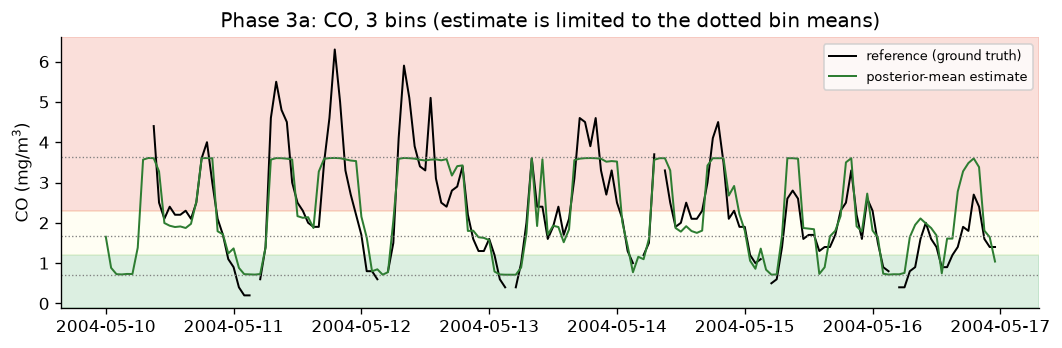

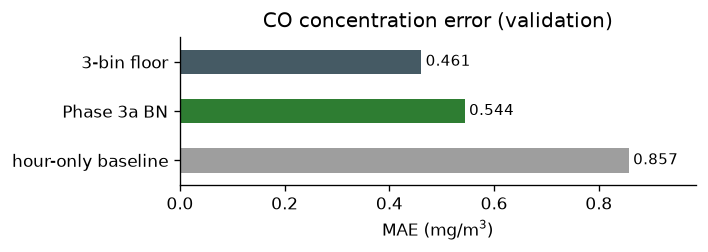

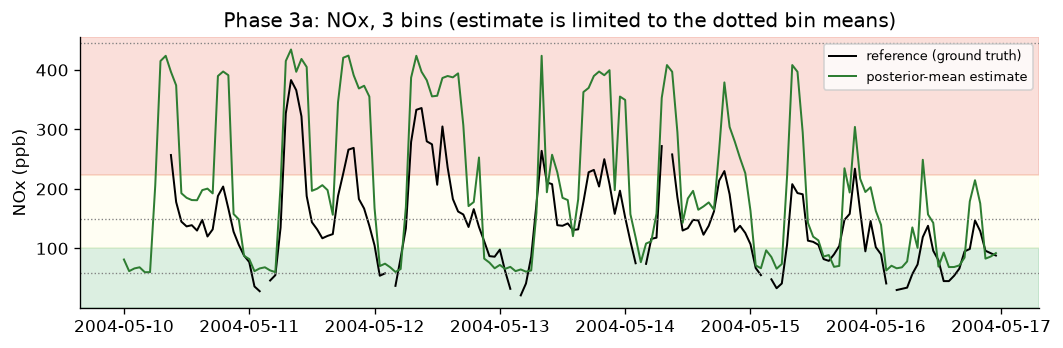

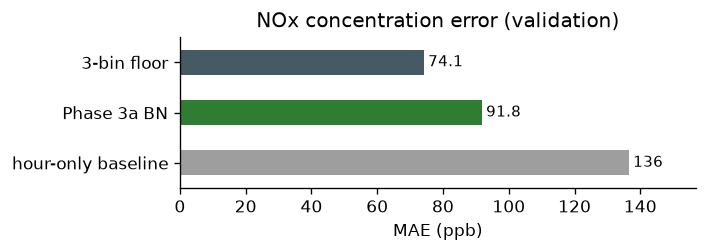

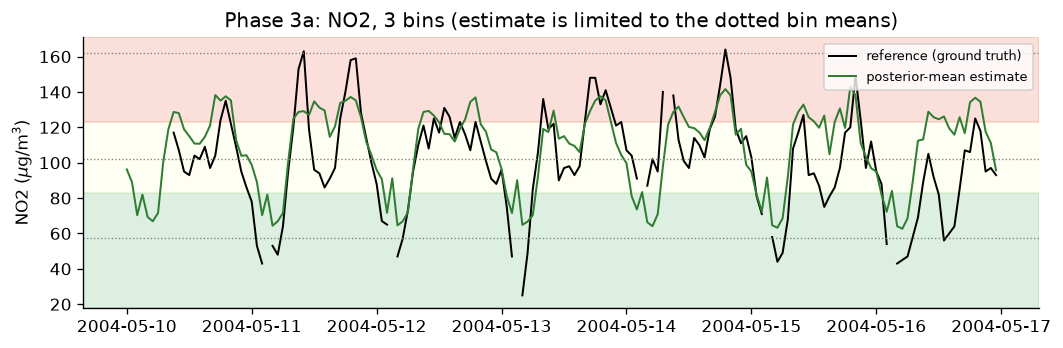

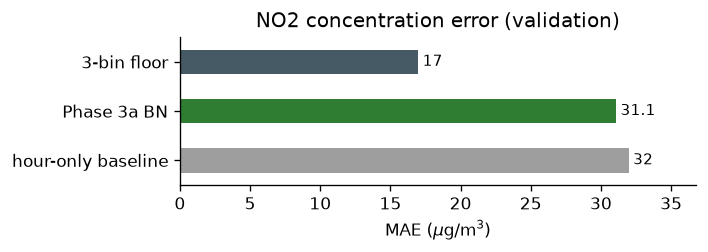

,bins,BN MAE,hour MAE,floor MAE,BN RMSE,hour RMSE,skill_vs_baseline,gap_closed,vs Phase 2
gas,,,,,,,,,
CO(GT),3,0.544 ± 0.045,0.857 ± 0.039,0.461 ± 0.058,0.805 ± 0.068,1.151 ± 0.036,0.365 ± 0.063,0.793 ± 0.026,0.092 ± 0.035
NO2(GT),3,31.080 ± 2.441,31.977 ± 2.802,16.981 ± 1.757,40.563 ± 3.556,41.443 ± 3.989,0.028 ± 0.010,0.060 ± 0.023,0.034 ± 0.023
NOx(GT),3,91.751 ± 0.074,136.469 ± 5.586,74.131 ± 18.198,134.117 ± 11.709,186.456 ± 19.586,0.327 ± 0.027,0.761 ± 0.235,0.061 ± 0.039


In [ ]:
grid = concentration_grid[concentration_grid["bins"] == N_BINS][
    ["bins", "seed", "gas", "model", "MAE", "RMSE"]
]

summary_table = concentration_section(
    gases=GASES,
    grid=grid,
    est_val={g: rep["bn_est"][g] for g in GASES},
    val_raw=rep["val_raw"],
    c_bar=rep["c_bar"],
    edges=edges,
    week=WEEK,
    phase_label=PHASE_LABEL,
    n_bins=N_BINS,
    fig_path=lambda f: config.paths.figure(PHASE, f),
)

# how much of Phase 2's MAE the cross edges remove (same splits, same bins)
phase2_grid = pd.read_csv(config.paths.result("phase2", "concentration_grid.csv"))
paired = concentration_grid.merge(
    phase2_grid[phase2_grid["model"] == "BN"],
    on=["bins", "seed", "gas"],
    suffixes=("", "_phase2"),
)
paired = paired[(paired["model"] == "BN") & (paired["bins"] == N_BINS)]
vs_p2 = (
    paired.apply(lambda r: skill_vs_baseline(r["MAE"], r["MAE_phase2"]), axis=1)
    .groupby(paired["gas"])
    .agg(["mean", "std"])
)
summary_table["vs Phase 2"] = [
    f"{vs_p2.loc[g, 'mean']:.3f} ± {vs_p2.loc[g, 'std']:.3f}"
    for g in summary_table.index
]

summary_table

### Summary Report

#### Interpretations
- Phase 3a's BN removes about 37% of the hour only baseline's MAE for CO (0.365 ± 0.063), about 3% for NO2 (0.028 ± 0.010), and about 33% for NOx (0.327 ± 0.027)
- The BN closes about 80% of the gap between the baseline and the resolution floor for CO (0.793 ± 0.026), and about 77% for NOx (0.761 ± 0.235), so there is little room for improvement in the model for these gases with 3 bins, but for NO2 the gap is closed by about 6% (0.060 ± 0.023), so there is much more room for improvement. 


#### Limitations
- Only 3 bins are used, which means the resolution is low, and using more bins would help with that, but it would make it so we have less evidence per bin, so we kept the 3 bins
- The concentration estimate uses year-round training bin means, so in low-pollution seasons a “high” posterior overshoots. More bins narrow the top bin; season-aware bin means would address the seasonal part and are future work.
- The trace plots show seed 0 on one validation week. The MAE bars and the table are means over the three split seeds.


*AI use: code started and debugged with help from Claude, edited, reviewed and run by me.*